In [1]:
import numpy as np
import pandas as pd

RANDOM_STATE = 42   # graine unique, réutilisée partout (split, validation croisée, modèles)

In [2]:
df = pd.read_csv('spam.csv', encoding='cp1252')
df.sample(5)

,v1,v2,Unnamed: 2,Unnamed: 3,Unnamed: 4
641,ham,"said kiss, kiss, i can't do the sound effects...",NaN,NaN,NaN
37,ham,I see the letter B on my car,NaN,NaN,NaN
2352,ham,Thats cool. How was your day?,NaN,NaN,NaN
1251,spam,Please CALL 08712402779 immediately as there i...,NaN,NaN,NaN
5256,ham,Well she's in for a big surprise!,NaN,NaN,NaN


In [3]:
df.shape

(5572, 5)

In [4]:
# 1. Data cleaning
# 2. EDA
# 3. Text Preprocessing
# 4. Model building (split, pipeline, équilibrage par SMOTE)
# 5. Evaluation
# 6. Improvement (expériences, réglage, ensembles)
# 7. Final model and export
# 8. Website (app.py, Streamlit en local)

## 1. Data Cleaning

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   v1          5572 non-null   str  
 1   v2          5572 non-null   str  
 2   Unnamed: 2  50 non-null     str  
 3   Unnamed: 3  12 non-null     str  
 4   Unnamed: 4  6 non-null      str  
dtypes: str(5)
memory usage: 677.1 KB


In [6]:
# drop last 3 cols (errors='ignore' : la cellule peut être relancée sans erreur)
df = df.drop(columns=['Unnamed: 2', 'Unnamed: 3', 'Unnamed: 4'], errors='ignore')

In [7]:
df.sample(5)

,v1,v2
1536,ham,How's it feel? Mr. Your not my real Valentine ...
865,spam,Congratulations ur awarded either a yrs supply...
2300,ham,Nothin comes to my mind. ÌÏ help me buy hanger...
2535,ham,Can you pls pls send me a mail on all you know...
492,ham,"Sorry,in meeting I'll call later"


In [8]:
# renaming the cols
df = df.rename(columns={'v1': 'target', 'v2': 'text'})
df.sample(5)

,target,text
156,ham,I'm leaving my house now...
5214,spam,Natalja (25/F) is inviting you to be her frien...
694,ham,Ah poop. Looks like ill prob have to send in m...
5263,ham,Pls speak with me. I wont ask anything other t...
5175,ham,Raji..pls do me a favour. Pls convey my Birthd...


In [9]:
# Le fichier source contient 'å£' à la place de '£' (défaut du jeu de données d'origine)
print("avant :", df['text'].str.contains('\u00e5\u00a3').sum(), "messages concernés")
df['text'] = df['text'].str.replace('\u00e5\u00a3', '\u00a3', regex=False)
print("après :", df['text'].str.contains('\u00e5\u00a3').sum())

avant : 257 messages concernés
après : 0


In [10]:
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()

In [11]:
df['target'] = encoder.fit_transform(df['target'])

In [12]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [13]:
# missing values
df.isnull().sum()

target    0
text      0
dtype: int64

In [14]:
# check for duplicate values
df.duplicated().sum()

np.int64(403)

In [15]:
# remove duplicates
df = df.drop_duplicates(keep='first')

In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
df.shape

(5169, 2)

In [18]:
# Contrôles : le notebook s'arrête ici si le nettoyage ne donne pas ce qui est attendu
assert df.shape == (5169, 2), df.shape
assert df['target'].sum() == 653 and (df['target'] == 0).sum() == 4516
assert not df['text'].str.contains('\u00e5\u00a3').any()
print("Section 1 OK :", df.shape)

Section 1 OK : (5169, 2)


## 2.EDA

In [19]:
df.head()

,target,text
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [20]:
df['target'].value_counts()

target
0    4516
1     653
Name: count, dtype: int64

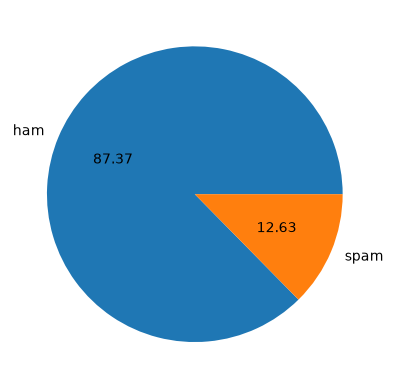

In [21]:
import matplotlib.pyplot as plt
plt.pie(df['target'].value_counts(), labels=['ham','spam'],autopct="%0.2f")
plt.show()

In [22]:
n_ham, n_spam = (df['target'] == 0).sum(), (df['target'] == 1).sum()
print(f"ham : {n_ham} | spam : {n_spam} | rapport : {n_ham / n_spam:.1f} contre 1")
print(f"Accuracy d'un modèle qui répond toujours 'ham' : {n_ham / len(df):.1%}")

ham : 4516 | spam : 653 | rapport : 6.9 contre 1
Accuracy d'un modèle qui répond toujours 'ham' : 87.4%


Les classes sont déséquilibrées : un modèle qui ne répondrait jamais « spam » aurait déjà 87,4 % d'accuracy.
L'accuracy est donc trompeuse ; on suivra la **précision, le rappel et le F1**.
On rééquilibrera par **génération synthétique (SMOTE)**, uniquement sur l'ensemble d'entraînement.

In [23]:
%pip install nltk

Note: you may need to restart the kernel to use updated packages.


In [24]:
import nltk
nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)

True

In [25]:
df['num_characters'] = df['text'].apply(len)

In [26]:
df.head()

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [27]:
# num of words
df['text'].apply(lambda x:nltk.word_tokenize(x))

0       [Go, until, jurong, point, ,, crazy, .., Avail...
1                [Ok, lar, ..., Joking, wif, u, oni, ...]
2       [Free, entry, in, 2, a, wkly, comp, to, win, F...
3       [U, dun, say, so, early, hor, ..., U, c, alrea...
4       [Nah, I, do, n't, think, he, goes, to, usf, ,,...
                              ...                        
5567    [This, is, the, 2nd, time, we, have, tried, 2,...
5568     [Will, Ì_, b, going, to, esplanade, fr, home, ?]
5569    [Pity, ,, *, was, in, mood, for, that, ., So, ...
5570    [The, guy, did, some, bitching, but, I, acted,...
5571                  [Rofl, ., Its, true, to, its, name]
Name: text, Length: 5169, dtype: object

In [28]:
df.head()

,target,text,num_characters
0,0,"Go until jurong point, crazy.. Available only ...",111
1,0,Ok lar... Joking wif u oni...,29
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155
3,0,U dun say so early hor... U c already then say...,49
4,0,"Nah I don't think he goes to usf, he lives aro...",61


In [29]:
df['num_sentences'] = df['text'].apply(lambda x:len(nltk.sent_tokenize(x)))

In [30]:
df.head()

,target,text,num_characters,num_sentences
0,0,"Go until jurong point, crazy.. Available only ...",111,2
1,0,Ok lar... Joking wif u oni...,29,2
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,2
3,0,U dun say so early hor... U c already then say...,49,1
4,0,"Nah I don't think he goes to usf, he lives aro...",61,1


In [31]:
df['num_words'] = df['text'].apply(lambda x:len(nltk.word_tokenize(x)))

In [32]:
df.head()

,target,text,num_characters,num_sentences,num_words
0,0,"Go until jurong point, crazy.. Available only ...",111,2,24
1,0,Ok lar... Joking wif u oni...,29,2,8
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,2,37
3,0,U dun say so early hor... U c already then say...,49,1,13
4,0,"Nah I don't think he goes to usf, he lives aro...",61,1,15


In [33]:
df[['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,5169.000000,5169.000000,5169.000000
mean,78.925518,18.461405,1.966531
std,58.176247,13.335314,1.449833
min,2.000000,1.000000,1.000000
25%,36.000000,9.000000,1.000000
50%,60.000000,15.000000,1.000000
75%,117.000000,26.000000,2.000000
max,910.000000,220.000000,38.000000


In [34]:
# ham
df[df['target'] == 0][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,4516.000000,4516.000000,4516.000000
mean,70.458370,17.128432,1.820195
std,56.358199,13.504730,1.383657
min,2.000000,1.000000,1.000000
25%,34.000000,8.000000,1.000000
50%,52.000000,13.000000,1.000000
75%,90.000000,22.000000,2.000000
max,910.000000,220.000000,38.000000


In [35]:
#spam
df[df['target'] == 1][['num_characters','num_words','num_sentences']].describe()

,num_characters,num_words,num_sentences
count,653.000000,653.000000,653.000000
mean,137.482389,27.679939,2.978560
std,30.014747,7.014020,1.493185
min,13.000000,2.000000,1.000000
25%,131.000000,25.000000,2.000000
50%,148.000000,29.000000,3.000000
75%,157.000000,32.000000,4.000000
max,223.000000,46.000000,9.000000


In [36]:
import seaborn as sns

<Axes: xlabel='num_characters', ylabel='Count'>

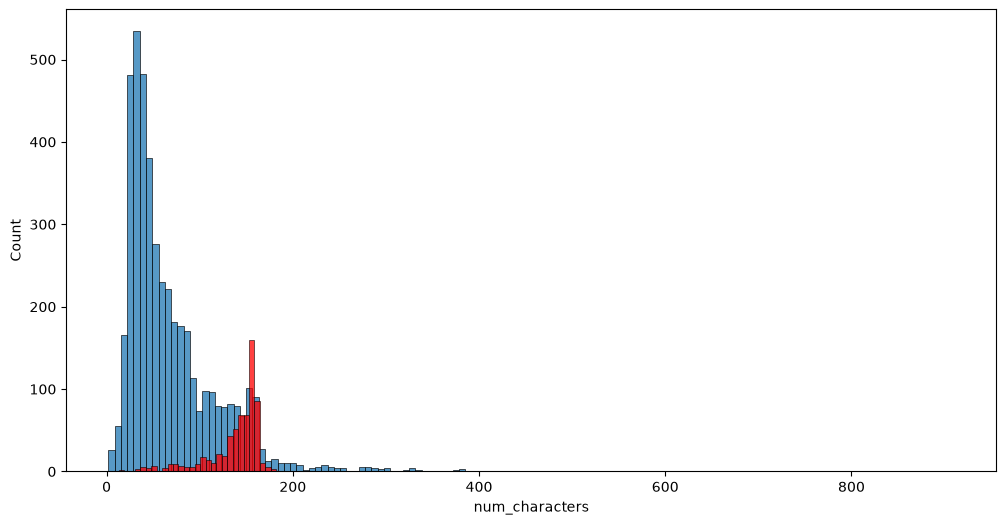

In [37]:
plt.figure(figsize=(12,6))
sns.histplot(df[df['target'] == 0]['num_characters'])
sns.histplot(df[df['target'] == 1]['num_characters'],color='red')

        50%    95%    max
ham    52.0  159.0  910.0
spam  148.0  162.0  223.0

Hams plus longs que le plus long spam (223 car.) : 1.75%


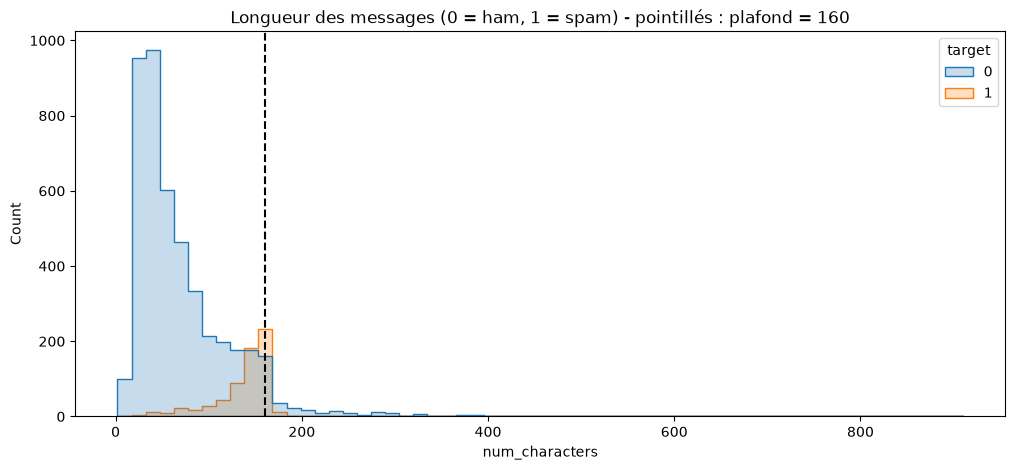

In [38]:
# Statistiques de longueur : elles justifient le plafond de 160 caractères utilisé plus loin
stats = df.groupby('target')['num_characters'].describe(percentiles=[.5, .95])[['50%', '95%', 'max']]
stats.index = ['ham', 'spam']
print(stats)
plus_long_spam = df[df['target'] == 1]['num_characters'].max()
part = (df[df['target'] == 0]['num_characters'] > plus_long_spam).mean()
print(f"\nHams plus longs que le plus long spam ({plus_long_spam} car.) : {part:.2%}")

plt.figure(figsize=(12, 5))
sns.histplot(data=df, x='num_characters', hue='target', bins=60, element='step')
plt.axvline(160, color='black', linestyle='--')
plt.title("Longueur des messages (0 = ham, 1 = spam) - pointillés : plafond = 160")
plt.show()

<Axes: xlabel='num_words', ylabel='Count'>

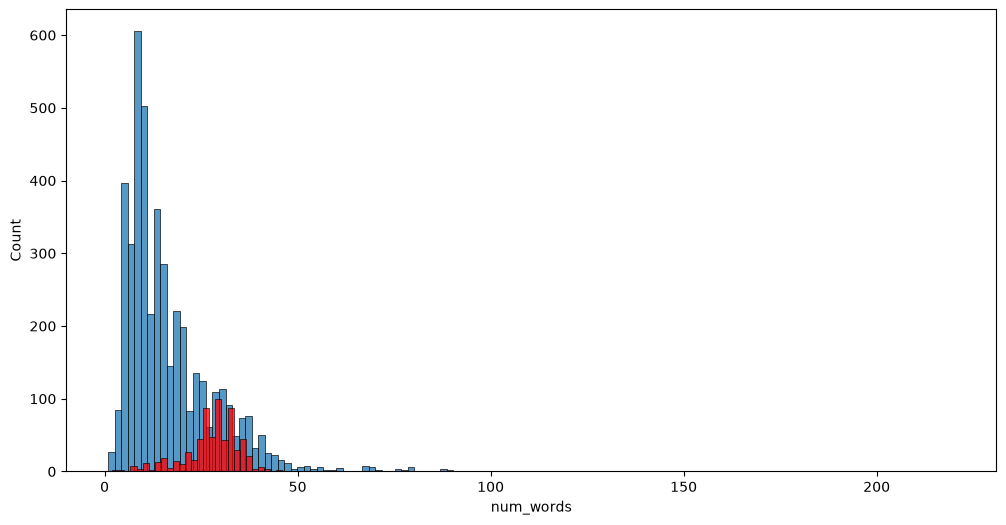

In [39]:
plt.figure(figsize=(12,6))
sns.histplot(df[df['target'] == 0]['num_words'])
sns.histplot(df[df['target'] == 1]['num_words'],color='red')

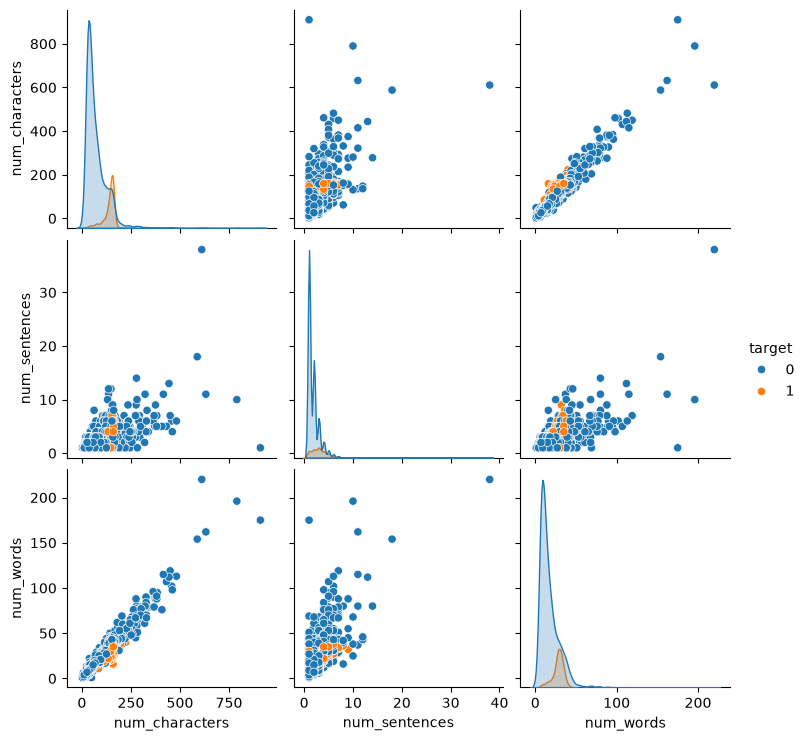

In [40]:
sns.pairplot(df,hue='target')

In [41]:
df.corr(numeric_only=True)

,target,num_characters,num_sentences,num_words
target,1.000000,0.382784,0.265459,0.262894
num_characters,0.382784,1.000000,0.624218,0.965990
num_sentences,0.265459,0.624218,1.000000,0.679816
num_words,0.262894,0.965990,0.679816,1.000000


<Axes: >

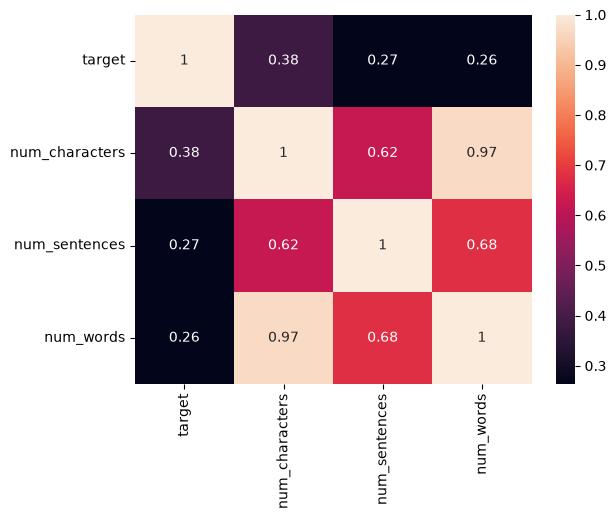

In [42]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

## 3. Data Preprocessing
- Lower case
- Tokenization
- Removing special characters
- Removing stop words and punctuation
- Stemming

In [43]:
%%writefile spam_utils.py
"""Fonctions de pretraitement partagees entre le notebook et l'application Streamlit.
Fichier ecrit par le notebook : le modele sauvegarde reference ces fonctions par leur nom."""
import re
from functools import lru_cache

import nltk
import numpy as np
from nltk.corpus import stopwords
from nltk.stem.porter import PorterStemmer

try:
    _STOP = set(stopwords.words("english"))
except LookupError:
    nltk.download("stopwords", quiet=True)
    _STOP = set(stopwords.words("english"))

_stemmer = PorterStemmer()
_TOKEN = re.compile(r"[a-z0-9]+")

# Plafond de longueur (caracteres) : 95 % des hams font moins de 160 caracteres et
# la mediane des spams est de 148. Au-dela, la longueur n'informe plus.
MAX_LEN = 160
EXTRA_NAMES = ["longueur", "part_chiffres", "part_majuscules", "symboles_monetaires", "lien"]


@lru_cache(maxsize=None)
def _stem(word):
    return _stemmer.stem(word)


def clean_text(text):
    """minuscules -> tokens alphanumeriques -> sans stopwords -> stemming."""
    tokens = _TOKEN.findall(str(text).lower())
    return " ".join(_stem(t) for t in tokens if t not in _STOP)


def extra_features(texts):
    """5 signaux non lexicaux typiques du spam. Toutes les valeurs sont >= 0."""
    rows = []
    for t in texts:
        t = str(t)
        n = len(t) or 1
        low = t.lower()
        rows.append([
            np.log1p(min(len(t), MAX_LEN)),                   # longueur (plafonnee)
            sum(c.isdigit() for c in t) / n,                  # part de chiffres
            sum(c.isupper() for c in t) / n,                  # part de majuscules
            sum(t.count(s) for s in "\u00a3$\u20ac"),         # symboles monetaires
            float("http" in low or "www" in low),             # presence d'un lien
        ])
    return np.array(rows, dtype=float)

Overwriting spam_utils.py


In [44]:
from spam_utils import clean_text, extra_features, MAX_LEN, EXTRA_NAMES

In [45]:
clean_text("I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today.")

'gonna home soon want talk stuff anymor tonight k cri enough today'

In [46]:
df['text'][10]

"I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today."

In [47]:
from nltk.stem.porter import PorterStemmer
ps = PorterStemmer()
ps.stem('loving')

'love'

In [48]:
df['transformed_text'] = df['text'].apply(clean_text)

In [49]:
df.head()

,target,text,num_characters,num_sentences,num_words,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,2,24,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,2,8,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,2,37,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,1,13,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,1,15,nah think goe usf live around though


In [50]:
%pip install wordcloud

Note: you may need to restart the kernel to use updated packages.


In [108]:
from wordcloud import WordCloud
wc = WordCloud(width=500,height=500,min_font_size=10,background_color='white')

In [109]:
spam_wc = wc.generate(df[df['target'] == 1]['transformed_text'].str.cat(sep=" "))

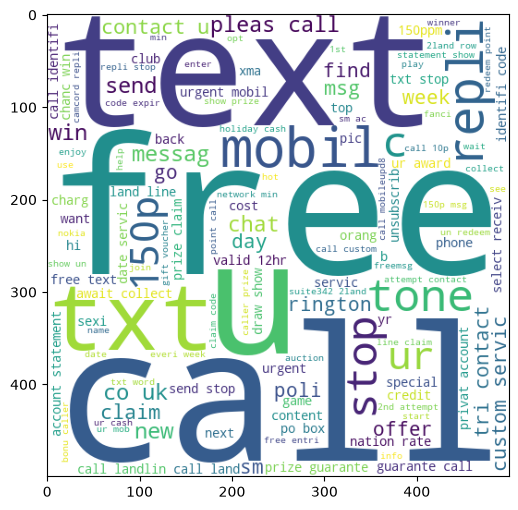

In [110]:
plt.figure(figsize=(15,6))
plt.imshow(spam_wc)

In [111]:
ham_wc = wc.generate(df[df['target'] == 0]['transformed_text'].str.cat(sep=" "))

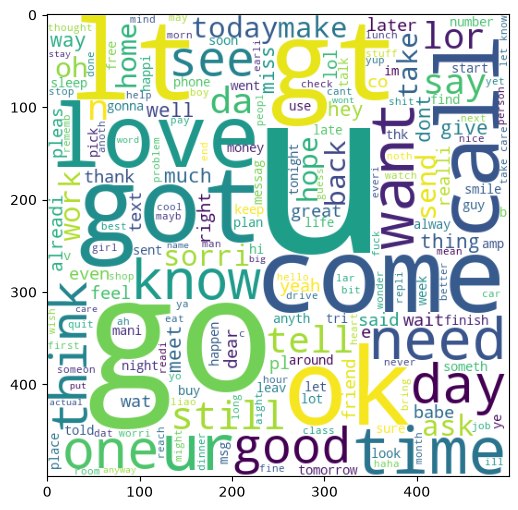

In [112]:
plt.figure(figsize=(15,6))
plt.imshow(ham_wc)

In [113]:
df.head()

,target,text,num_characters,num_sentences,num_words,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,2,24,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,2,8,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,2,37,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,1,13,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,1,15,nah think goe usf live around though


In [114]:
spam_corpus = []
for msg in df[df['target'] == 1]['transformed_text'].tolist():
    for word in msg.split():
        spam_corpus.append(word)
        

In [115]:
len(spam_corpus)

11744

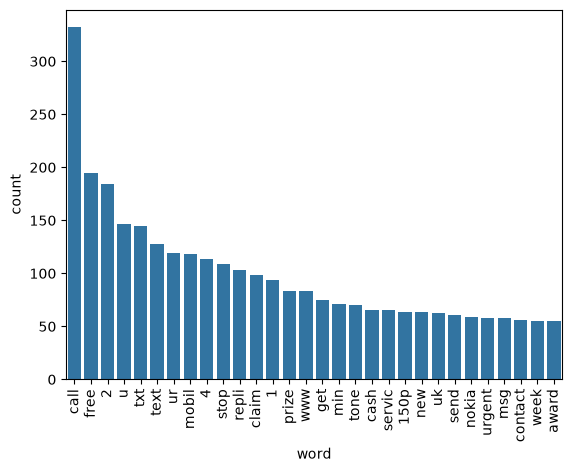

In [116]:
from collections import Counter
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

spam_df = pd.DataFrame(Counter(spam_corpus).most_common(30))
spam_df.columns = ['word', 'count']

sns.barplot(x='word', y='count', data=spam_df)
plt.xticks(rotation='vertical')
plt.show()


In [117]:
ham_corpus = []
for msg in df[df['target'] == 0]['transformed_text'].tolist():
    for word in msg.split():
        ham_corpus.append(word)

In [118]:
len(ham_corpus)

36228

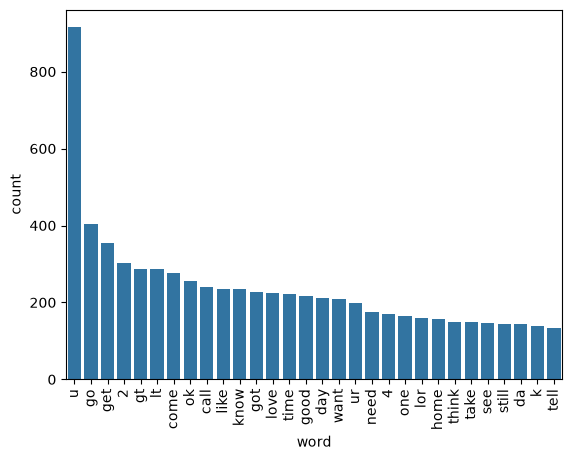

In [119]:
from collections import Counter
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

ham_df = pd.DataFrame(Counter(ham_corpus).most_common(30))
ham_df.columns = ['word', 'count']

sns.barplot(x='word', y='count', data=ham_df)
plt.xticks(rotation='vertical')
plt.show()


In [120]:
# Text Vectorization
# using Bag of Words
df.head()

,target,text,num_characters,num_sentences,num_words,transformed_text
0,0,"Go until jurong point, crazy.. Available only ...",111,2,24,go jurong point crazi avail bugi n great world...
1,0,Ok lar... Joking wif u oni...,29,2,8,ok lar joke wif u oni
2,1,Free entry in 2 a wkly comp to win FA Cup fina...,155,2,37,free entri 2 wkli comp win fa cup final tkt 21...
3,0,U dun say so early hor... U c already then say...,49,1,13,u dun say earli hor u c alreadi say
4,0,"Nah I don't think he goes to usf, he lives aro...",61,1,15,nah think goe usf live around though


In [121]:
assert clean_text("I'm gonna be HOME soon!!!") == "gonna home soon"
assert extra_features(["a" * 200])[0, 0] == extra_features(["a" * 900])[0, 0]   # le plafond est actif
print("Section 3 OK")

Section 3 OK


## 4. Model Building

In [122]:
from sklearn.model_selection import train_test_split, StratifiedKFold

X = df['text']      # texte brut : c'est le pipeline qui nettoie et vectorise
y = df['target']

# Le split vient EN PREMIER : tout ce qui est appris (vocabulaire TF-IDF, échelles, spams générés)
# viendra uniquement de X_train. Il est stratifié : mêmes proportions de spams dans train et test.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print("train :", X_train.shape[0], "| test :", X_test.shape[0])
print(f"spams  train : {y_train.sum()} ({y_train.mean():.2%}) | test : {y_test.sum()} ({y_test.mean():.2%})")

# Validation croisée à 5 plis, sur le train uniquement
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

train : 4135 | test : 1034
spams  train : 522 (12.62%) | test : 131 (12.67%)


In [124]:
%pip install imbalanced-learn

  Using cached imbalanced_learn-0.14.2-py3-none-any.whl.metadata (8.9 kB)
  Using cached sklearn_compat-0.1.6-py3-none-any.whl.metadata (22 kB)
Using cached imbalanced_learn-0.14.2-py3-none-any.whl (236 kB)
Using cached sklearn_compat-0.1.6-py3-none-any.whl (22 kB)

   ---------------------------------------- 0/2 [sklearn-compat]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn]
   -------------------- ------------------- 1/2 [imbalanced-learn

In [125]:
from imblearn.pipeline import Pipeline            # comme celui de scikit-learn, mais accepte une étape de rééquilibrage
from imblearn.over_sampling import SMOTE, RandomOverSampler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.pipeline import FeatureUnion, Pipeline as SkPipeline
from sklearn.preprocessing import FunctionTransformer, MaxAbsScaler

def construire_pipeline(clf, equilibrage='smote', use_extra=True, max_features=3000, ngram_range=(1, 1)):
    """Texte brut -> TF-IDF (+ 5 caractéristiques) -> génération de spams -> classifieur.
    equilibrage : 'smote' (spams synthétiques), 'duplication' (copies aléatoires) ou None.
    L'étape d'équilibrage n'agit que pendant fit() : jamais sur le test, jamais au moment de prédire."""
    tfidf = TfidfVectorizer(preprocessor=clean_text, max_features=max_features, ngram_range=ngram_range)
    if use_extra:
        extra = SkPipeline([('fn', FunctionTransformer(extra_features)), ('scale', MaxAbsScaler())])
        features = FeatureUnion([('tfidf', tfidf), ('extra', extra)])
    else:
        features = tfidf
    sampler = {'smote': SMOTE(random_state=RANDOM_STATE),
               'duplication': RandomOverSampler(random_state=RANDOM_STATE),
               None: 'passthrough'}[equilibrage]
    return Pipeline([('features', features), ('equilibrage', sampler), ('clf', clf)])

In [126]:
# Ce que fait SMOTE : il génère des spams synthétiques à partir du train uniquement
from sklearn.linear_model import LogisticRegression

pipe_demo = construire_pipeline(LogisticRegression())
X_train_vec = pipe_demo.named_steps['features'].fit_transform(X_train, y_train)
X_res, y_res = SMOTE(random_state=RANDOM_STATE).fit_resample(X_train_vec, y_train)

avant, apres = np.bincount(y_train), np.bincount(y_res)
print("train avant SMOTE :", avant, "(ham, spam)")
print("train après SMOTE :", apres, f"-> {apres[1] - avant[1]} spams générés")
print("test (jamais rééquilibré) :", np.bincount(y_test))

train avant SMOTE : [3613  522] (ham, spam)
train après SMOTE : [3613 3613] -> 3091 spams générés
test (jamais rééquilibré) : [903 131]


In [127]:
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.naive_bayes import MultinomialNB, BernoulliNB, ComplementNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, AdaBoostClassifier, BaggingClassifier,
                              ExtraTreesClassifier, GradientBoostingClassifier)
from xgboost import XGBClassifier

def modeles():
    """Les modèles de l'ancien notebook, avec des réglages raisonnables.
    GaussianNB est retiré (il exige une matrice dense de 3000 colonnes) ; SVC sigmoid (précision 0) est remplacé par SVC rbf."""
    rs = RANDOM_STATE
    return {
        'MultinomialNB': MultinomialNB(),
        'BernoulliNB': BernoulliNB(),
        'ComplementNB': ComplementNB(),
        'LogisticRegression': LogisticRegression(max_iter=2000, random_state=rs),
        'LinearSVC': LinearSVC(max_iter=5000, random_state=rs),
        'SVC_rbf': SVC(kernel='rbf', random_state=rs),
        'KNN': KNeighborsClassifier(metric='cosine', algorithm='brute'),
        'DecisionTree': DecisionTreeClassifier(max_depth=10, random_state=rs),
        'RandomForest': RandomForestClassifier(n_estimators=200, random_state=rs, n_jobs=-1),
        'ExtraTrees': ExtraTreesClassifier(n_estimators=200, random_state=rs, n_jobs=-1),
        'AdaBoost': AdaBoostClassifier(n_estimators=100, random_state=rs),
        'Bagging': BaggingClassifier(n_estimators=50, random_state=rs),
        'GradientBoosting': GradientBoostingClassifier(n_estimators=100, random_state=rs),
        'XGBoost': XGBClassifier(n_estimators=200, random_state=rs, eval_metric='logloss', n_jobs=-1),
    }

## 5. Evaluation

In [128]:
import time
from sklearn.model_selection import cross_validate
from sklearn.metrics import precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

SCORING = {'precision': 'precision', 'recall': 'recall', 'f1': 'f1', 'roc_auc': 'roc_auc'}

def score_continu(pipe, X_):
    """Score continu pour l'AUC : probabilité si le modèle en fournit, sinon decision_function."""
    return pipe.predict_proba(X_)[:, 1] if hasattr(pipe, 'predict_proba') else pipe.decision_function(X_)

def evaluer(nom, pipe):
    """1) validation croisée sur le TRAIN  2) entraînement sur le train, évaluation unique sur le TEST."""
    t0 = time.time()
    r = cross_validate(pipe, X_train, y_train, cv=cv, scoring=SCORING)
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    return {
        'Modèle': nom,
        'CV_F1': r['test_f1'].mean(), 'CV_F1_std': r['test_f1'].std(),
        'CV_précision': r['test_precision'].mean(), 'CV_rappel': r['test_recall'].mean(),
        'Test_précision': precision_score(y_test, pred, zero_division=0),
        'Test_rappel': recall_score(y_test, pred),
        'Test_F1': f1_score(y_test, pred),
        'Test_AUC': roc_auc_score(y_test, score_continu(pipe, X_test)),
        'FP': fp, 'FN': fn, 'temps_s': round(time.time() - t0, 1),
    }

In [129]:
from pathlib import Path
Path('reports/figures').mkdir(parents=True, exist_ok=True)

lignes = []
for nom, clf in modeles().items():
    lignes.append(evaluer(nom, construire_pipeline(clf, equilibrage='smote')))
    print(f"{nom:<20} CV_F1={lignes[-1]['CV_F1']:.4f}  Test_F1={lignes[-1]['Test_F1']:.4f}  "
          f"FP={lignes[-1]['FP']} FN={lignes[-1]['FN']}  ({lignes[-1]['temps_s']} s)")

benchmark = pd.DataFrame(lignes).sort_values('CV_F1', ascending=False).reset_index(drop=True)
benchmark.to_csv('reports/benchmark.csv', index=False)
benchmark.round(4)

MultinomialNB        CV_F1=0.8829  Test_F1=0.8993  FP=22 FN=6  (3.1 s)
BernoulliNB          CV_F1=0.9327  Test_F1=0.9355  FP=1 FN=15  (3.1 s)
ComplementNB         CV_F1=0.8829  Test_F1=0.8993  FP=22 FN=6  (3.1 s)
LogisticRegression   CV_F1=0.9477  Test_F1=0.9528  FP=2 FN=10  (3.5 s)
LinearSVC            CV_F1=0.9550  Test_F1=0.9606  FP=1 FN=9  (3.4 s)
SVC_rbf              CV_F1=0.9527  Test_F1=0.9482  FP=1 FN=12  (16.2 s)
KNN                  CV_F1=0.8046  Test_F1=0.7984  FP=18 FN=32  (5.3 s)
DecisionTree         CV_F1=0.8767  Test_F1=0.9044  FP=18 FN=8  (4.6 s)
RandomForest         CV_F1=0.9513  Test_F1=0.9402  FP=2 FN=13  (13.4 s)
ExtraTrees           CV_F1=0.9566  Test_F1=0.9612  FP=3 FN=7  (13.8 s)
AdaBoost             CV_F1=0.8979  Test_F1=0.9191  FP=16 FN=6  (22.7 s)
Bagging              CV_F1=0.8965  Test_F1=0.9151  FP=16 FN=7  (88.7 s)
GradientBoosting     CV_F1=0.9124  Test_F1=0.9502  FP=6 FN=7  (36.9 s)
XGBoost              CV_F1=0.9241  Test_F1=0.9453  FP=4 FN=10  (36.4 s)


,Modèle,CV_F1,CV_F1_std,CV_précision,CV_rappel,Test_précision,Test_rappel,Test_F1,Test_AUC,FP,FN,temps_s
0,ExtraTrees,0.9566,0.0094,0.9859,0.9291,0.9764,0.9466,0.9612,0.9981,3,7,13.8
1,LinearSVC,0.9550,0.0052,0.9783,0.9329,0.9919,0.9313,0.9606,0.9978,1,9,3.4
2,SVC_rbf,0.9527,0.0055,0.9820,0.9253,0.9917,0.9084,0.9482,0.9977,1,12,16.2
3,RandomForest,0.9513,0.0122,0.9858,0.9195,0.9833,0.9008,0.9402,0.9978,2,13,13.4
4,LogisticRegression,0.9477,0.0083,0.9592,0.9367,0.9837,0.9237,0.9528,0.9965,2,10,3.5
5,BernoulliNB,0.9327,0.0090,0.9957,0.8773,0.9915,0.8855,0.9355,0.9988,1,15,3.1
6,XGBoost,0.9241,0.0135,0.9378,0.9118,0.9680,0.9237,0.9453,0.9946,4,10,36.4
7,GradientBoosting,0.9124,0.0208,0.9044,0.9213,0.9538,0.9466,0.9502,0.9937,6,7,36.9
8,AdaBoost,0.8979,0.0096,0.8801,0.9175,0.8865,0.9542,0.9191,0.9897,16,6,22.7
9,Bagging,0.8965,0.0195,0.8746,0.9213,0.8857,0.9466,0.9151,0.9930,16,7,88.7


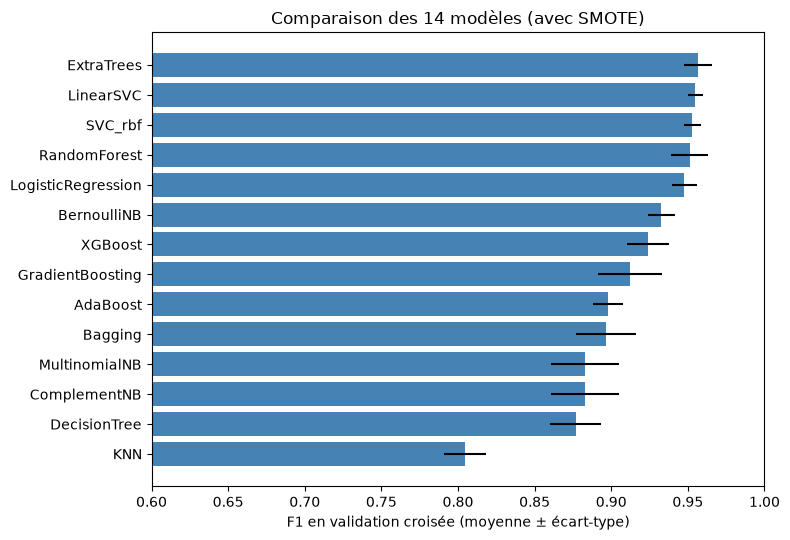

In [130]:
import matplotlib.pyplot as plt

b = benchmark.sort_values('CV_F1')
plt.figure(figsize=(8, 5.5))
plt.barh(b['Modèle'], b['CV_F1'], xerr=b['CV_F1_std'], color='steelblue')
plt.xlim(0.6, 1.0)
plt.xlabel('F1 en validation croisée (moyenne ± écart-type)')
plt.title('Comparaison des 14 modèles (avec SMOTE)')
plt.tight_layout()
plt.savefig('reports/figures/benchmark_f1.png', dpi=150)
plt.show()

## 6. Improvement

In [131]:
def cv_resume(pipe):
    r = cross_validate(pipe, X_train, y_train, cv=cv,
                       scoring={'f1': 'f1', 'recall': 'recall', 'precision': 'precision'})
    return {'F1': r['test_f1'].mean(), 'F1_std': r['test_f1'].std(),
            'Rappel': r['test_recall'].mean(), 'Précision': r['test_precision'].mean()}

def LR(**kw):
    return LogisticRegression(C=10, max_iter=2000, random_state=RANDOM_STATE, **kw)

# Une seule variable change à la fois (régression logistique, validation croisée sur le train)
EXPERIENCES = [
    ('Équilibrage : aucun',                  LR(),                         dict(equilibrage=None)),
    ('Équilibrage : class_weight balanced',  LR(class_weight='balanced'),  dict(equilibrage=None)),
    ('Équilibrage : duplication aléatoire',  LR(),                         dict(equilibrage='duplication')),
    ('Équilibrage : SMOTE (spams générés)',  LR(),                         dict(equilibrage='smote')),
    ('SMOTE sans caractéristiques extra',    LR(),                         dict(use_extra=False)),
    ('SMOTE, max_features = 1000',           LR(),                         dict(max_features=1000)),
    ('SMOTE, max_features = 5000',           LR(),                         dict(max_features=5000)),
    ('SMOTE, max_features = None',           LR(),                         dict(max_features=None)),
    ('SMOTE, n-grammes (1, 2)',              LR(),                         dict(ngram_range=(1, 2))),
]

lignes = []
for nom, clf, params in EXPERIENCES:
    lignes.append({'Expérience': nom, **cv_resume(construire_pipeline(clf, **params))})
experiences = pd.DataFrame(lignes)
experiences.to_csv('reports/experiences.csv', index=False)
experiences.round(4)

,Expérience,F1,F1_std,Rappel,Précision
0,Équilibrage : aucun,0.9334,0.0142,0.8888,0.9834
1,Équilibrage : class_weight balanced,0.9545,0.0064,0.9444,0.9651
2,Équilibrage : duplication aléatoire,0.9554,0.0055,0.9425,0.9688
3,Équilibrage : SMOTE (spams générés),0.9562,0.0074,0.9387,0.9748
4,SMOTE sans caractéristiques extra,0.8979,0.0214,0.9119,0.8864
5,"SMOTE, max_features = 1000",0.9562,0.0054,0.9425,0.9707
6,"SMOTE, max_features = 5000",0.9589,0.0048,0.9387,0.9804
7,"SMOTE, max_features = None",0.9580,0.0026,0.9406,0.9764
8,"SMOTE, n-grammes (1, 2)",0.9535,0.0066,0.9425,0.9649


In [132]:
from sklearn.model_selection import GridSearchCV

MF = 'features__tfidf__max_features'
CANDIDATS = {
    'LogisticRegression': (LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
                           {'clf__C': [1, 10, 100], MF: [1000, 3000, None]}),
    'LinearSVC':          (LinearSVC(max_iter=5000, random_state=RANDOM_STATE),
                           {'clf__C': [0.1, 1, 10], MF: [1000, 3000, None]}),
    'BernoulliNB':        (BernoulliNB(),
                           {'clf__alpha': [0.1, 1.0], MF: [500, 1000, 3000]}),
}

candidats_estimateurs, lignes = {}, []
for nom, (clf, grille) in CANDIDATS.items():
    gs = GridSearchCV(construire_pipeline(clf, equilibrage='smote'), grille, scoring='f1', cv=cv, refit=True)
    gs.fit(X_train, y_train)
    candidats_estimateurs[nom] = gs.best_estimator_
    ligne = evaluer(nom, gs.best_estimator_)
    ligne['meilleurs_paramètres'] = str(gs.best_params_)
    lignes.append(ligne)
    print(f"{nom:<20} CV_F1={ligne['CV_F1']:.4f}  Test_F1={ligne['Test_F1']:.4f}  {gs.best_params_}")

LogisticRegression   CV_F1=0.9610  Test_F1=0.9569  {'clf__C': 100, 'features__tfidf__max_features': None}
LinearSVC            CV_F1=0.9591  Test_F1=0.9606  {'clf__C': 0.1, 'features__tfidf__max_features': 3000}
BernoulliNB          CV_F1=0.9437  Test_F1=0.9440  {'clf__alpha': 0.1, 'features__tfidf__max_features': 500}


In [133]:
from sklearn.ensemble import VotingClassifier, StackingClassifier

def trois_modeles():
    rs = RANDOM_STATE
    return [('lr', LogisticRegression(C=10, max_iter=2000, random_state=rs)),
            ('nb', BernoulliNB(alpha=0.1)),
            ('et', ExtraTreesClassifier(n_estimators=200, random_state=rs, n_jobs=-1))]

# Voting (vote pondéré par les probabilités) et Stacking : mêmes modèles que l'ancien notebook, adaptés au pipeline
for nom, ensemble in [
    ('Voting (soft)', VotingClassifier(trois_modeles(), voting='soft')),
    ('Stacking',      StackingClassifier(trois_modeles(),
                                         final_estimator=LogisticRegression(max_iter=2000, random_state=RANDOM_STATE))),
]:
    pipe = construire_pipeline(ensemble, equilibrage='smote')
    ligne = evaluer(nom, pipe)
    ligne['meilleurs_paramètres'] = '-'
    lignes.append(ligne)
    candidats_estimateurs[nom] = pipe
    print(f"{nom:<20} CV_F1={ligne['CV_F1']:.4f}  Test_F1={ligne['Test_F1']:.4f}  FP={ligne['FP']} FN={ligne['FN']}")

reglage = pd.DataFrame(lignes).sort_values('CV_F1', ascending=False).reset_index(drop=True)
reglage.to_csv('reports/reglage.csv', index=False)
reglage.drop(columns='meilleurs_paramètres').round(4)

Voting (soft)        CV_F1=0.9572  Test_F1=0.9440  FP=1 FN=13
Stacking             CV_F1=0.9616  Test_F1=0.9524  FP=1 FN=11


,Modèle,CV_F1,CV_F1_std,CV_précision,CV_rappel,Test_précision,Test_rappel,Test_F1,Test_AUC,FP,FN,temps_s
0,Stacking,0.9616,0.0098,0.9883,0.9367,0.9917,0.9160,0.9524,0.9983,1,11,103.0
1,LogisticRegression,0.9610,0.0045,0.9785,0.9444,0.9839,0.9313,0.9569,0.9971,2,9,3.4
2,LinearSVC,0.9591,0.0022,0.9746,0.9444,0.9919,0.9313,0.9606,0.9974,1,9,3.4
3,Voting (soft),0.9572,0.0103,0.9939,0.9233,0.9916,0.9008,0.9440,0.9983,1,13,14.5
4,BernoulliNB,0.9437,0.0172,0.9894,0.9023,0.9916,0.9008,0.9440,0.9988,1,13,3.2


## 7. Final model and export

In [134]:
import json
import joblib
from sklearn.base import clone
from sklearn.metrics import average_precision_score

# Choix du modèle final. Les candidats réglés sont proches (voir le tableau de la section 6) : on retient la
# régression logistique, car elle fournit des scores exploitables et des coefficients interprétables,
# que l'application Streamlit utilise pour expliquer chaque décision.
MODELE_FINAL = 'LogisticRegression'
meilleur = candidats_estimateurs[MODELE_FINAL]        # entraîné sur le train uniquement

proba = meilleur.predict_proba(X_test)[:, 1]
pred = (proba >= 0.5).astype(int)
tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
metriques = {
    'modele': MODELE_FINAL, 'n_train': int(len(X_train)), 'n_test': int(len(X_test)),
    'precision': round(precision_score(y_test, pred), 4),
    'recall': round(recall_score(y_test, pred), 4),
    'f1': round(f1_score(y_test, pred), 4),
    'roc_auc': round(roc_auc_score(y_test, proba), 4),
    'pr_auc': round(average_precision_score(y_test, proba), 4),
    'matrice_confusion': {'TN': int(tn), 'FP': int(fp), 'FN': int(fn), 'TP': int(tp)},
}
with open('reports/metrics.json', 'w', encoding='utf-8') as f:
    json.dump(metriques, f, indent=2, ensure_ascii=False)
metriques

{'modele': 'LogisticRegression',
 'n_train': 4135,
 'n_test': 1034,
 'precision': 0.9839,
 'recall': 0.9313,
 'f1': 0.9569,
 'roc_auc': 0.9971,
 'pr_auc': 0.9882,
 'matrice_confusion': {'TN': 901, 'FP': 2, 'FN': 9, 'TP': 122}}

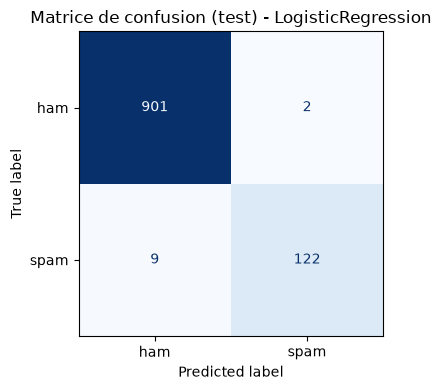

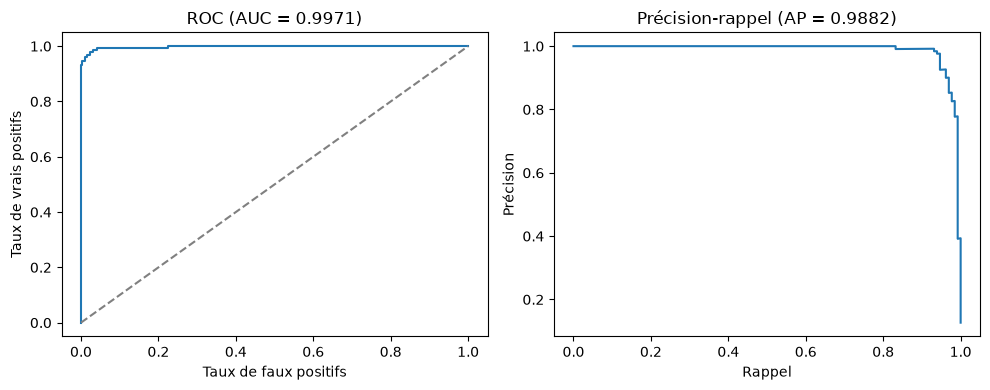

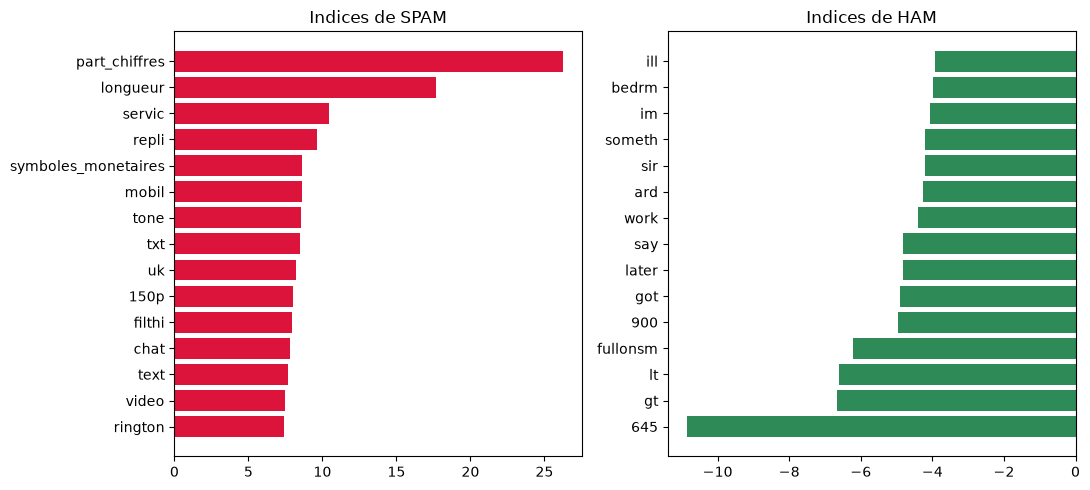

In [135]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, precision_recall_curve, roc_curve

# 1) Matrice de confusion (test)
fig, ax = plt.subplots(figsize=(4.5, 4))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['ham', 'spam']).plot(
    ax=ax, cmap='Blues', colorbar=False)
ax.set_title(f'Matrice de confusion (test) - {MODELE_FINAL}')
fig.tight_layout(); fig.savefig('reports/figures/confusion_matrix.png', dpi=150); plt.show()

# 2) Courbes ROC et précision-rappel
fpr, tpr, _ = roc_curve(y_test, proba)
prec, rec, _ = precision_recall_curve(y_test, proba)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(fpr, tpr); axes[0].plot([0, 1], [0, 1], '--', color='gray')
axes[0].set(title=f"ROC (AUC = {metriques['roc_auc']})", xlabel='Taux de faux positifs', ylabel='Taux de vrais positifs')
axes[1].plot(rec, prec)
axes[1].set(title=f"Précision-rappel (AP = {metriques['pr_auc']})", xlabel='Rappel', ylabel='Précision')
fig.tight_layout(); fig.savefig('reports/figures/roc_pr.png', dpi=150); plt.show()

# 3) Mots qui poussent le plus vers spam / ham (coefficients de la régression logistique)
tfidf_ajuste = meilleur.named_steps['features'].transformer_list[0][1]
noms = np.array(list(tfidf_ajuste.get_feature_names_out()) + EXTRA_NAMES)
coefs = meilleur.named_steps['clf'].coef_.ravel()
ordre = np.argsort(coefs)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
axes[0].barh(noms[ordre[-15:]], coefs[ordre[-15:]], color='crimson'); axes[0].set_title('Indices de SPAM')
axes[1].barh(noms[ordre[:15]], coefs[ordre[:15]], color='seagreen'); axes[1].set_title('Indices de HAM')
fig.tight_layout(); fig.savefig('reports/figures/top_words.png', dpi=150); plt.show()

In [136]:
Path('models').mkdir(exist_ok=True)

# Même configuration, ré-entraînée sur TOUTES les données (SMOTE appliqué pendant cet entraînement)
final = clone(meilleur).fit(X, y)

# SMOTE ne sert qu'à l'entraînement : on le retire pour que le modèle exporté soit un pipeline scikit-learn simple
deploiement = SkPipeline([(nom, etape) for nom, etape in final.steps if nom != 'equilibrage'])
assert np.allclose(deploiement.predict_proba(X_test), final.predict_proba(X_test))

joblib.dump(deploiement, 'models/spam_model.joblib')
print("Modèle exporté :", Path('models/spam_model.joblib').stat().st_size // 1024, "Ko")

Modèle exporté : 195 Ko


In [137]:
import subprocess, sys

EMAILS = {
    "spam : gain de 1000 £": "Subject: URGENT - You have WON a £1,000 cash prize!\n\nDear valued customer,\n\nCongratulations! Your mobile number has been selected in our weekly draw. To claim your FREE prize, call 09061701461 now or visit www.claim-your-prize-uk.com. Offer expires today! Text WIN to 80086 to confirm your entry.\n\nT&Cs apply. 18+ only.",
    "spam : phishing bancaire": "Subject: Your account has been suspended\n\nDear customer,\n\nWe detected unusual activity on your bank account. For your security your account has been temporarily suspended. To restore access you must verify your identity within 24 hours by clicking the link below and entering your card number and password. Failure to do so will result in permanent closure of your account.\n\nhttp://secure-bank-verify.com/login\n\nSecurity Department",
    "ham : rendez-vous": "Subject: Meeting tomorrow\n\nHi Sarah,\n\nThanks for sending the report yesterday. I had a look at it this morning and it looks good overall. Could we meet tomorrow at 10 to go through the budget section? Let me know if that works for you, otherwise I can do Thursday afternoon.\n\nBest,\nTom",
    "ham : point projet (long)": "Subject: Project update and next steps\n\nHi team,\n\nI wanted to give everyone a quick update on where we stand with the project. The first phase is finished and the results look encouraging. Anna reviewed the data on Monday and found only a couple of small inconsistencies, which she has already fixed. Next week we will start the second phase, so please send me your availability for a planning meeting by Friday. I would like to go through the schedule together, agree on who is responsible for what, and make sure nobody is overloaded during the busy period at the end of the month. If you have any questions or concerns in the meantime, feel free to call me or drop by my office. Thanks again for all your hard work, it is really appreciated.\n\nBest regards,\nTom",
    "ham : newsletter": "Subject: This week at the library\n\nDear members,\n\nThis week we are hosting a reading afternoon for children on Wednesday, and a talk about local history on Friday evening. The reading room will be closed on Saturday for maintenance work. New books have arrived in the fiction section, including several titles you asked about last month. As always, you can renew your loans online or at the front desk. We hope to see many of you this week.\n\nThe Library Team",
    "ham : facture (cas difficile)": "Subject: Your invoice for October\n\nHello,\n\nPlease find attached the invoice for the services provided during October. The total amount due is 450 euros and payment is expected within 30 days of the invoice date. If you have already made the payment, please ignore this message. Do not hesitate to contact me if you need any clarification regarding the items listed. We really appreciate your trust and look forward to working with you again next month.\n\nKind regards,\nMaria Lopez, Accounts Department",
}
scores = {nom: float(deploiement.predict_proba([texte])[0, 1]) for nom, texte in EMAILS.items()}
for nom, s in scores.items():
    print(f"{nom:<32} score de spam = {s:6.1%}  ->  {'SPAM' if s >= 0.5 else 'ham'}")

# Contrôle décisif : le modèle exporté se recharge-t-il dans un AUTRE processus Python, comme le fera l'application ?
code = ("import joblib; m = joblib.load('models/spam_model.joblib'); "
        "print(round(float(m.predict_proba(['WINNER!! Claim your free prize now, call 09061701461'])[0, 1]), 3))")
r = subprocess.run([sys.executable, '-c', code], capture_output=True, text=True)
print("\nRechargement dans un autre processus :", r.stdout.strip() or "ÉCHEC", r.stderr.strip())

spam : gain de 1000 £            score de spam = 100.0%  ->  SPAM
spam : phishing bancaire         score de spam =  99.8%  ->  SPAM
ham : rendez-vous                score de spam =   0.1%  ->  ham
ham : point projet (long)        score de spam =   1.1%  ->  ham
ham : newsletter                 score de spam =   1.4%  ->  ham
ham : facture (cas difficile)    score de spam =  32.5%  ->  ham

Rechargement dans un autre processus : 0.997 


In [138]:
# Contrôles finaux : le notebook s'arrête ici si le modèle ou ses prédictions ne sont pas ceux attendus
assert metriques['f1'] >= 0.93 and metriques['recall'] >= 0.88 and metriques['precision'] >= 0.95
assert scores["spam : gain de 1000 £"] > 0.5 and scores["spam : phishing bancaire"] > 0.5
assert all(s < 0.5 for nom, s in scores.items() if nom.startswith("ham"))
assert r.returncode == 0 and r.stdout.strip() != ""      # le modèle exporté se recharge hors du notebook
print("Section 7 OK")

Section 7 OK


8. Website

L'interface Streamlit est dans `app.py` (hors notebook) : `streamlit run app.py`